In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [88]:
BASE_DIR = Path.cwd()
RAW_PATH = BASE_DIR / "Dataset" / "cleaned_ebay_data.csv"
df = pd.read_csv(RAW_PATH)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (341, 17)


,Brand,Processor,Screen Size (in),Color,Ram Size (GB),SSD Capacity (GB),GPU,Processor Speed (GHz),Type,Resolution Size,Maximum Resolution,Model,OS,Hard Drive Capacity (GB),Storage Type,Condition,Price ($)
0,Dell,Intel Core i5,14.0,Black,16.0,500.0,Intel HD Graphics,2.4,Notebook/Laptop,Medium,1920 x 1080,Dell Latitude E5470,Windows 10 Pro,500,SSD,Used,175.00
1,Dell,Intel Celeron,11.0,Black,4.0,128.0,Intel UHD Graphics 600,1.1,Notebook/Laptop,Small,1366 x 768,Dell Latitude 3189,Windows 10 Pro,128,SSD,Used,129.99
2,Acer,Intel Celeron,11.6,Gray,4.0,16.0,Intel HD Graphics,1.6,Notebook/Laptop,Small,1366 x 768,Acer Chromebook C731,Chrome OS,16,SSD,Used,39.99
3,Dell,Intel Core i5,12.5,Black,8.0,256.0,Intel HD Graphics,2.6,Notebook/Laptop,Medium,1920 x 1080,Dell Latitude 5289,Windows 10,256,SSD,Used,199.99
4,Dell,Intel Core i5,15.6,Black,16.0,512.0,Intel HD Graphics 620,3.1,Notebook/Laptop,Medium,1920 x 1080,Dell Latitude 5580,Windows 10 Pro,512,SSD,Very Good,344.99


In [89]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 341 entries, 0 to 340
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Brand                     341 non-null    str    
 1   Processor                 341 non-null    str    
 2   Screen Size (in)          341 non-null    float64
 3   Color                     341 non-null    str    
 4   Ram Size (GB)             341 non-null    float64
 5   SSD Capacity (GB)         341 non-null    float64
 6   GPU                       341 non-null    str    
 7   Processor Speed (GHz)     341 non-null    float64
 8   Type                      341 non-null    str    
 9   Resolution Size           341 non-null    str    
 10  Maximum Resolution        341 non-null    str    
 11  Model                     341 non-null    str    
 12  OS                        341 non-null    str    
 13  Hard Drive Capacity (GB)  341 non-null    int64  
 14  Storage Type         

In [90]:
categorical_columns = df.select_dtypes(include=['object','str']).columns
for col in categorical_columns:
    print(f"column: {col}")
    print(df[col].value_counts().head(10))

column: Brand
Brand
Dell         110
Lenovo        94
HP            83
Acer          19
Microsoft     14
Samsung        8
ASUS           4
Panasonic      4
Gateway        2
Fujitsu        2
Name: count, dtype: int64
column: Processor
Processor
Intel Core i5      118
Intel Core i7       96
Intel Celeron       80
Intel Core i3       14
AMD Ryzen 5          7
AMD Ryzen 7          5
Intel Pentium        4
Microsoft SQ2        3
AMD Ryzen 7 Pro      2
Intel Core Duo       2
Name: count, dtype: int64
column: Color
Color
Black           189
Silver           67
Gray             49
Multicolor        8
Blue              6
Purple            5
Silver/Black      4
Standard          3
Red               2
Green             2
Name: count, dtype: int64
column: GPU
GPU
Intel HD Graphics             90
Intel UHD Graphics 620        46
Intel Iris Xe Graphics        38
Intel UHD Graphics            19
AMD Radeon Graphics           16
Intel HD Graphics 520         14
Intel UHD Graphics 600        12
Intel H

In [91]:
df.describe()

,Screen Size (in),Ram Size (GB),SSD Capacity (GB),Processor Speed (GHz),Hard Drive Capacity (GB),Price ($)
count,341.000000,341.000000,341.000000,341.000000,341.000000,341.000000
mean,13.762757,13.612903,331.048416,2.301760,323.410557,287.997654
std,1.603578,12.102127,343.130156,0.821527,435.052933,290.862353
min,7.000000,2.000000,0.000000,1.000000,0.000000,25.500000
25%,12.500000,4.000000,128.000000,1.700000,32.000000,110.000000
50%,14.000000,8.000000,256.000000,2.300000,256.000000,199.990000
75%,15.000000,16.000000,512.000000,2.600000,500.000000,349.990000
max,17.300000,64.000000,2000.000000,5.100000,4000.000000,1899.990000


In [92]:
pd.crosstab(df['Storage Type'],df['SSD Capacity (GB)'])

SSD Capacity (GB),0.00,16.00,32.00,64.00,120.00,128.00,240.00,256.00,500.00,512.00,931.51,1000.00,2000.00
Storage Type,,,,,,,,,,,,,
HDD,10,0,0,0,2,1,0,0,2,0,1,2,0
M.2,0,0,0,0,0,0,0,1,0,0,0,0,0
NVMe,0,0,0,0,0,0,0,1,0,0,0,0,1
SSD,1,27,9,4,0,29,1,112,15,61,0,21,2
SSD + HDD,0,0,0,0,0,2,0,2,0,0,0,1,3
SSD + eMMC,0,1,0,0,0,0,0,0,0,0,0,0,0
eMMC,0,12,12,4,0,1,0,0,0,0,0,0,0


In [93]:
storage_analysis = df.groupby("Storage Type")[
    ["SSD Capacity (GB)", "Hard Drive Capacity (GB)"]
].agg(["count", "min", "median", "max"])

storage_analysis

SSD Capacity (GB)                         \
                         count    min  median     max   
Storage Type                                            
HDD                         18    0.0     0.0  1000.0   
M.2                          1  256.0   256.0   256.0   
NVMe                         2  256.0  1128.0  2000.0   
SSD                        282    0.0   256.0  2000.0   
SSD + HDD                    8  128.0   628.0  2000.0   
SSD + eMMC                   1   16.0    16.0    16.0   
eMMC                        29   16.0    32.0   128.0   

             Hard Drive Capacity (GB)                     
                                count  min  median   max  
Storage Type                                              
HDD                                18   12   500.0  1000  
M.2                                 1    0     0.0     0  
NVMe                                2  256  1128.0  2000  
SSD                               282    0   256.0  2000  
SSD + HDD                           8  500  1500.0  4000  
SSD + eMMC                          1   16    16.0    16  
eMMC                               29    0    32.0    64

In [94]:
print("Both capacities are zero:")
print(
    ((df["SSD Capacity (GB)"] == 0) &
     (df["Hard Drive Capacity (GB)"] == 0)).sum()
)

print("\nBoth capacities are greater than zero:")
print(
    ((df["SSD Capacity (GB)"] > 0) &
     (df["Hard Drive Capacity (GB)"] > 0)).sum()
)

print("\nOnly SSD capacity is zero:")
print(
    ((df["SSD Capacity (GB)"] == 0) &
     (df["Hard Drive Capacity (GB)"] > 0)).sum()
)

print("\nOnly hard drive capacity is zero:")
print(
    ((df["SSD Capacity (GB)"] > 0) &
     (df["Hard Drive Capacity (GB)"] == 0)).sum()
)

Both capacities are zero:
0

Both capacities are greater than zero:
308

Only SSD capacity is zero:
11

Only hard drive capacity is zero:
22


In [95]:
df[[
    "Model",
    "Storage Type",
    "SSD Capacity (GB)",
    "Hard Drive Capacity (GB)",
    "Price ($)"
]].sample(15, random_state=42)

,Model,Storage Type,SSD Capacity (GB),Hard Drive Capacity (GB),Price ($)
322,Acer Swift 1,SSD,128.0,128,89.99
116,Precision 7680,SSD,512.0,32,1799.99
113,Lenovo ThinkPad X1 Tablet Gen 3,SSD,256.0,256,419.99
42,Dell Latitude E4310,HDD,0.0,250,74.99
126,Dell Latitude 7490,SSD,1000.0,1000,245.00
223,Latitude 3420,SSD,512.0,512,349.95
182,Lenovo ThinkPad T470,SSD,128.0,128,179.50
179,Samsung Chromebook 3,SSD,16.0,16,49.00
338,14,SSD,512.0,512,399.00
25,Samsung Chromebook 3,SSD,16.0,16,47.00


In [96]:
same_capacity = (
    df["SSD Capacity (GB)"] == df["Hard Drive Capacity (GB)"]
)

print("Identical capacities:", same_capacity.sum())
print("Different capacities:", (~same_capacity).sum())

Identical capacities: 276
Different capacities: 65


In [97]:
different_storage = df[
    df["SSD Capacity (GB)"] != df["Hard Drive Capacity (GB)"]
]

different_storage[[
    "Model",
    "Storage Type",
    "SSD Capacity (GB)",
    "Hard Drive Capacity (GB)",
    "Price ($)"
]].sort_values("Storage Type")

,Model,Storage Type,SSD Capacity (GB),Hard Drive Capacity (GB),Price ($)
199,HP ProBook 440 G3,HDD,128.0,500,100.00
183,Latitude E6420,HDD,0.0,160,89.99
176,X555LA,HDD,0.0,160,89.99
220,Dell Inspiron 15 3552,HDD,0.0,500,89.99
164,15-ba018wm,HDD,0.0,1000,119.99
...,...,...,...,...,...
273,Alienware 15 R3,SSD + HDD,256.0,1000,300.00
209,Lenovo ThinkPad E14 G2,SSD + HDD,128.0,500,149.99
106,HP Omen,SSD + HDD,2000.0,4000,1200.00
28,Chromebook 14 G5,eMMC,16.0,1,49.00


In [98]:
df[df["Storage Type"].isin(["SSD + HDD", "SSD + eMMC"])][[
    "Model",
    "Storage Type",
    "SSD Capacity (GB)",
    "Hard Drive Capacity (GB)",
    "Price ($)"
]]

,Model,Storage Type,SSD Capacity (GB),Hard Drive Capacity (GB),Price ($)
87,Lenovo N22,SSD + eMMC,16.0,16,208.99
106,HP Omen,SSD + HDD,2000.0,4000,1200.00
138,Dell Inspiron 15 3593,SSD + HDD,128.0,1000,279.00
197,Dell inspiron 7720,SSD + HDD,2000.0,2000,600.00
209,Lenovo ThinkPad E14 G2,SSD + HDD,128.0,500,149.99
235,Alienware 15 R3,SSD + HDD,256.0,1000,300.00
261,HP Omen,SSD + HDD,2000.0,4000,1200.00
273,Alienware 15 R3,SSD + HDD,256.0,1000,300.00
297,HP ZBook 15,SSD + HDD,1000.0,2000,834.51


In [99]:
mismatch_analysis = df.assign(
    Same_Capacity=(
        df["SSD Capacity (GB)"] ==
        df["Hard Drive Capacity (GB)"]
    )
).groupby("Storage Type")["Same_Capacity"].value_counts().unstack(fill_value=0)

mismatch_analysis

Same_Capacity,False,True
Storage Type,,
HDD,12,6
M.2,1,0
NVMe,0,2
SSD,43,239
SSD + HDD,7,1
SSD + eMMC,0,1
eMMC,2,27


In [100]:
suspicious_storage = df[
    (
        (df["Storage Type"] == "HDD") &
        (df["SSD Capacity (GB)"] > 0)
    ) |
    (
        (df["Storage Type"] == "eMMC") &
        (df["Hard Drive Capacity (GB)"] > 64)
    )
]

suspicious_storage[[
    "Model",
    "Storage Type",
    "SSD Capacity (GB)",
    "Hard Drive Capacity (GB)",
    "Price ($)"
]]

,Model,Storage Type,SSD Capacity (GB),Hard Drive Capacity (GB),Price ($)
31,HP ProBook,HDD,500.00,500,99.99
88,Dell Latitude D810,HDD,120.00,120,124.90
137,HP 17-by2xxx,HDD,931.51,12,300.00
190,N550J,HDD,500.00,500,295.00
199,HP ProBook 440 G3,HDD,128.00,500,100.00
241,HP 15-ay009dx,HDD,1000.00,1000,62.95
254,HP ProBook,HDD,1000.00,1000,175.00
318,i5 4200M,HDD,120.00,120,99.00


In [101]:
df["Storage_Mismatch"] = (
    df["SSD Capacity (GB)"] !=
    df["Hard Drive Capacity (GB)"]
)


In [102]:
print("Exact duplicate records:", df.duplicated().sum())

Exact duplicate records: 84


In [103]:
duplicates = df[df.duplicated(keep=False)]

duplicates.sort_values("Model")

,Brand,Processor,Screen Size (in),Color,Ram Size (GB),SSD Capacity (GB),GPU,Processor Speed (GHz),Type,Resolution Size,Maximum Resolution,Model,OS,Hard Drive Capacity (GB),Storage Type,Condition,Price ($),Storage_Mismatch
33,Dell,Intel Core i5,14.0,Black,32.0,512.0,Intel UHD Graphics 620,1.7,Notebook/Laptop,Medium,1920 x 1080,14,Not Included,512,SSD,Used,399.00,False
338,Dell,Intel Core i5,14.0,Black,32.0,512.0,Intel UHD Graphics 620,1.7,Notebook/Laptop,Medium,1920 x 1080,14,Not Included,512,SSD,Used,399.00,False
236,HP,AMD E-Series,14.0,Silver,8.0,512.0,AMD Radeon Graphics,1.8,Notebook/Laptop,Medium,1920 x 1080,14-an013nr,Windows 11 Home,512,SSD,Used,120.00,False
212,HP,AMD E-Series,14.0,Silver,8.0,512.0,AMD Radeon Graphics,1.8,Notebook/Laptop,Medium,1920 x 1080,14-an013nr,Windows 11 Home,512,SSD,Used,120.00,False
262,Lenovo,Intel Core i5,14.0,Black,8.0,256.0,Intel UHD Graphics 620,1.6,Notebook/Laptop,Medium,1920 x 1080,20NY-S3Y600,Windows 10,256,SSD,Used,187.99,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22,Lenovo,Intel Core i7,14.1,Purple,16.0,256.0,NVIDIA GEFORCE GT 730M,2.9,Notebook,Small,1600 x 900,ThinkPad T460p,Windows 10 Pro,0,SSD,Used,187.77,True
20,Lenovo,Intel Core i7,14.1,Purple,16.0,256.0,NVIDIA GEFORCE GT 730M,2.9,Notebook,Small,1600 x 900,ThinkPad T460p,Windows 10 Pro,0,SSD,Used,187.77,True
244,Lenovo,Intel Core i7,14.1,Purple,16.0,256.0,NVIDIA GEFORCE GT 730M,2.9,Notebook,Small,1600 x 900,ThinkPad T460p,Windows 10 Pro,0,SSD,Used,187.77,True
282,Lenovo,Intel Core i5,14.0,Standard,12.0,512.0,Intel HD Graphics 520,2.4,Notebook/Laptop,Medium,1920 x 1080,t470s i5,Windows 11 Pro,512,SSD,Excellent,219.99,False


In [104]:
df = df.drop(columns=["Storage_Mismatch"], errors="ignore")

print("Shape before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

print("Remaining duplicates:", df.duplicated().sum())

Shape before removing duplicates: (341, 17)
Shape after removing duplicates: (257, 17)
Remaining duplicates: 0


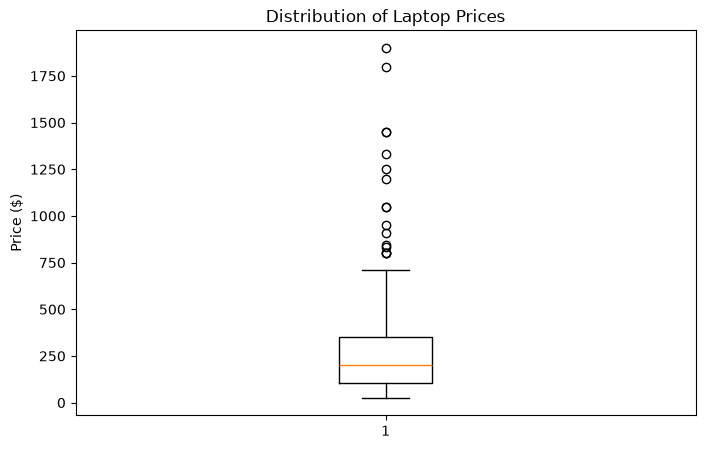

In [105]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.boxplot(df["Price ($)"])
plt.title("Distribution of Laptop Prices")
plt.ylabel("Price ($)")
plt.show()

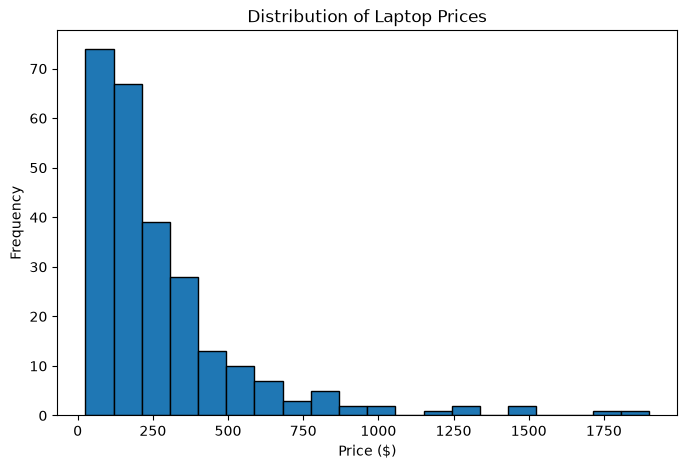

In [106]:
plt.figure(figsize=(8, 5))

plt.hist(df["Price ($)"].dropna(), bins=20, edgecolor="black")

plt.title("Distribution of Laptop Prices")
plt.xlabel("Price ($)")
plt.ylabel("Frequency")
plt.show()

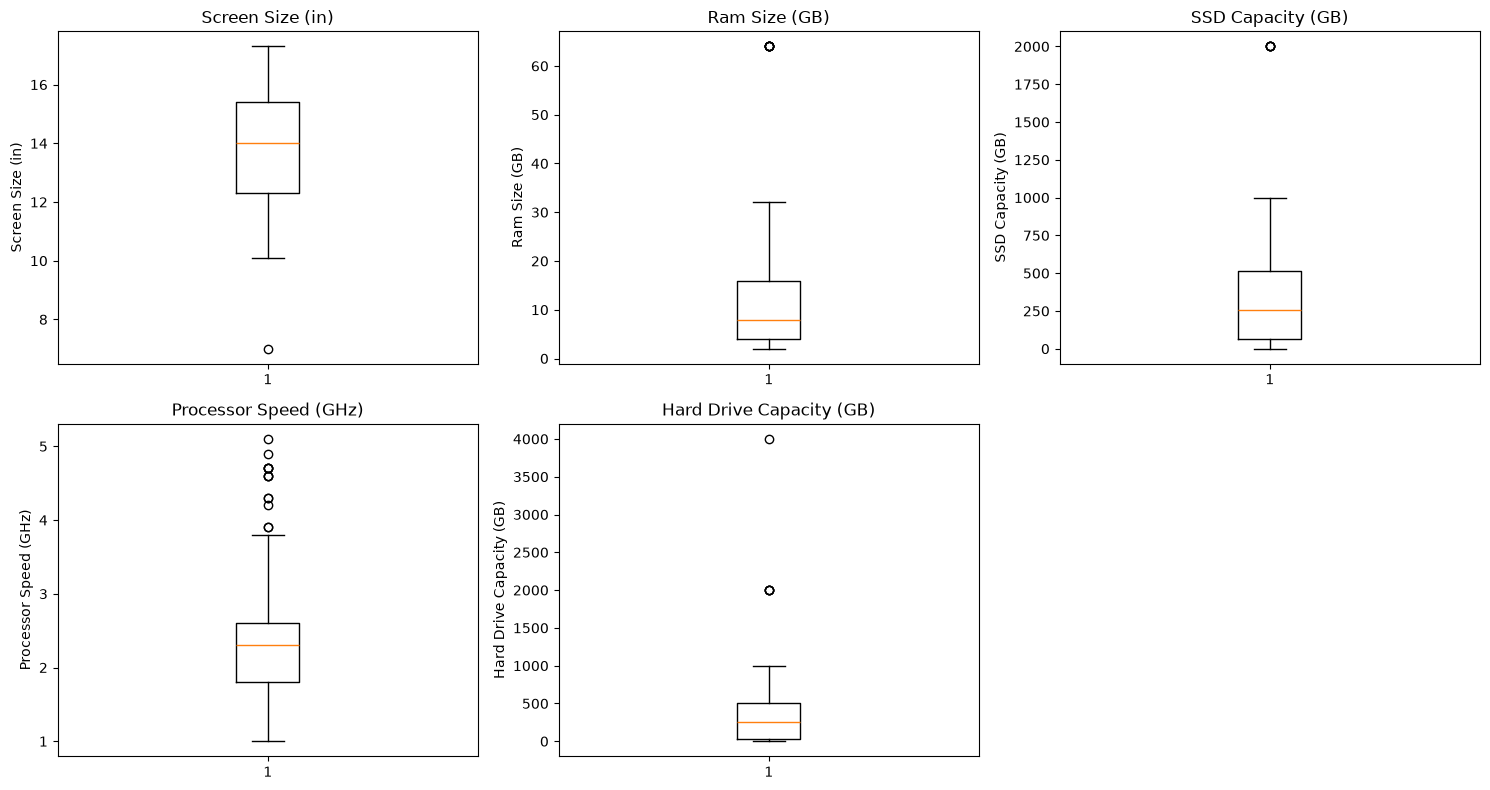

In [107]:
numeric_cols = [
    "Screen Size (in)",
    "Ram Size (GB)",
    "SSD Capacity (GB)",
    "Processor Speed (GHz)",
    "Hard Drive Capacity (GB)"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(df[col])
    axes[i].set_title(col)
    axes[i].set_ylabel(col)

axes[-1].axis("off")  # hide the empty 6th subplot
plt.tight_layout()
plt.show()

In [108]:
print("=== High-Price Laptops (> $1000) ===")
df[df["Price ($)"] > 1000][[
    "Brand", "Model", "Processor", "Ram Size (GB)", "GPU", "Condition", "Price ($)"
]].sort_values("Price ($)", ascending=False)

=== High-Price Laptops (> $1000) ===


,Brand,Model,Processor,Ram Size (GB),GPU,Condition,Price ($)
214,Dell,Latitude 5430 Rugged,Intel Core i7,32.0,Intel Iris Xe Graphics,Excellent,1899.99
116,Dell,Precision 7680,Intel Core i7,32.0,NVIDIA RTX A1000,Excellent,1799.99
285,Dell,Latitude 5430 Rugged,Intel Core i5,32.0,Intel Iris Xe Graphics,Excellent,1449.99
144,Dell,Latitude 13 7330 Rugged Extreme,Intel Core i5,16.0,Intel Iris Xe Graphics,Excellent,1449.99
44,Dell,Latitude 5430 Rugged,Intel Core i7,16.0,Intel Iris Xe Graphics,Very Good,1329.99
296,Dell,Latitude 5430 Rugged,Intel Core i5,8.0,Intel Iris Xe Graphics,Very Good,1249.99
106,HP,HP Omen,Intel Core i7,64.0,NVIDIA GeForce RTX 2070,Used,1200.00
45,Dell,Latitude 7230 Rugged Extreme Tablet,Intel Core i3,8.0,Intel Iris Xe Graphics,Excellent,1049.99
216,Dell,Dell Latitude 5520,Intel Core i7,16.0,Intel Iris Xe Graphics,Excellent,1049.99


In [109]:
print("=== High RAM Laptops (>= 32 GB) ===")
df[df["Ram Size (GB)"] >= 32][[
    "Brand", "Model", "Processor", "Ram Size (GB)", "SSD Capacity (GB)", "Condition", "Price ($)"
]].sort_values("Price ($)")

=== High RAM Laptops (>= 32 GB) ===


,Brand,Model,Processor,Ram Size (GB),SSD Capacity (GB),Condition,Price ($)
170,Lenovo,Lenovo 100e,Intel Celeron,64.0,64.0,Open box,109.99
327,Microsoft,Microsoft Surface Go 3,Intel Pentium,64.0,64.0,Used,124.00
111,Lenovo,Lenovo ThinkPad A485,AMD Ryzen 5,32.0,512.0,Used,239.00
311,HP,ELITEBOOK 745 G6,AMD Ryzen 7,32.0,512.0,Used,239.98
64,Dell,Dell Latitude 7490,Intel Core i5,32.0,1000.0,Used,245.00
141,HP,HP Elitebook 840 G6,Intel Core i5,32.0,500.0,Used,249.99
142,Dell,Dell Latitude E7470,Intel Core i7,32.0,256.0,Used,279.00
58,Dell,Dell Latitude 5440,Intel Core i5,32.0,500.0,Excellent,279.99
149,Dell,5580,Intel Core i7,32.0,512.0,Used,289.99
9,HP,Hp Elitlebook G5,Intel Core i5,32.0,500.0,Very Good,289.99


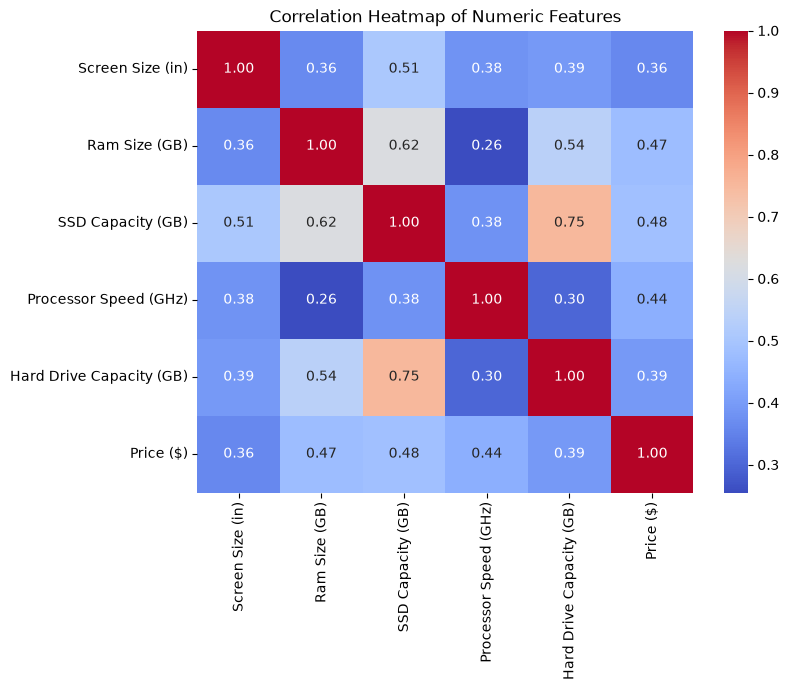

In [110]:
plt.figure(figsize=(8, 6))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

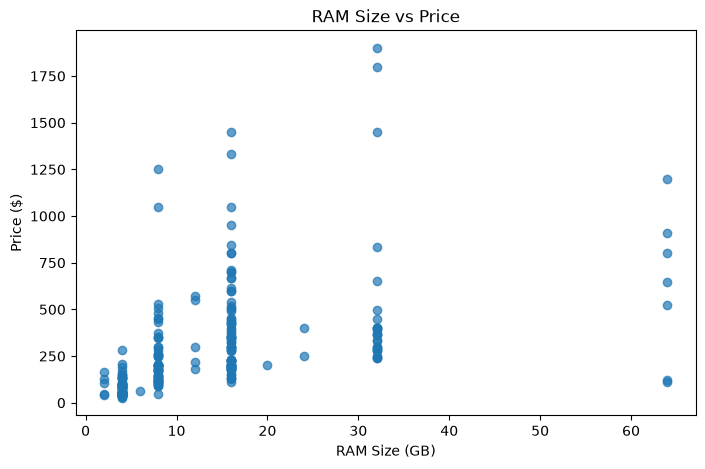

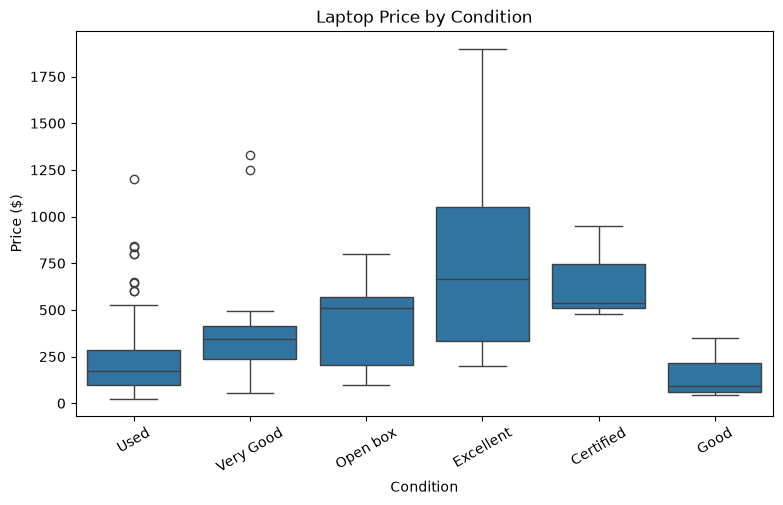

           count        mean   median
Brand                                
Dell          89  381.630787  279.000
Lenovo        68  226.744706  194.500
HP            63  243.526984  172.000
Acer          13  124.224615   54.000
Samsung        7   98.204286   47.000
Microsoft      6  363.136667  384.915
ASUS           4  323.455000  337.475
Panasonic      3  500.650000  668.000
Fujitsu        2  149.500000  149.500
Gateway        1  349.990000  349.990
GPD            1  348.990000  348.990


In [111]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Ram Size (GB)"], df["Price ($)"], alpha=0.7)
plt.title("RAM Size vs Price")
plt.xlabel("RAM Size (GB)")
plt.ylabel("Price ($)")
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Condition", y="Price ($)")
plt.title("Laptop Price by Condition")
plt.xticks(rotation=30)
plt.show()

print(df.groupby("Brand")["Price ($)"].agg(["count", "mean", "median"]).sort_values("count", ascending=False))

In [112]:
bad_ram = (df["Ram Size (GB)"] == 64.0) & (df["Processor"].isin(["Intel Celeron", "Intel Pentium"]))
print("Mislabeled 64GB Celeron/Pentium rows found:", bad_ram.sum())

if bad_ram.sum() > 0:
    df = df[~bad_ram].copy()
    print("After removing mislabeled RAM rows:", df.shape)
save_path = BASE_DIR / "Dataset" / "final_ebay_data.csv"
if len(df) > 0:
    df.to_csv(save_path, index=False)
    check = pd.read_csv(save_path)
    print("Verified saved final_ebay_data.csv shape:", check.shape)
else:
    print("ERROR: df is empty, nothing saved!")

Mislabeled 64GB Celeron/Pentium rows found: 2
After removing mislabeled RAM rows: (255, 17)
Verified saved final_ebay_data.csv shape: (255, 17)
